# The nD workflow: tables for ODE right-hand sides

`ChebyshevInterpolantND` works in any number of dimensions and holds several
functions sampled on the same grid. Around it, ChebyshevND provides what an
ODE solve needs from a table:

1. **a multi-function table** with named axes, error estimates per axis and
   pruning;
2. **precontraction**: fixing parameters (say, the mass ratio of one
   waveform) once, for much cheaper evaluations afterwards, also for a whole
   batch of waveforms;
3. **derivatives**, as new interpolants or together with the value;
4. **compiled evaluation** from inside a Numba right-hand side;
5. **domain maps**, for tables whose physical region is not a box;
6. **grids** for sampling in parallel chunks, and **files** to keep the
   result.

The functions below are toy stand-ins, cheap enough to sample in the notebook.

In [1]:
import tempfile
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from numba import njit
from scipy.integrate import solve_ivp

from chebyshevnd import (
    Axis,
    AxisMap,
    ChebyshevGrid,
    ChebyshevInterpolantND,
    OutOfDomainError,
    chebyshev_nodes,
    eval_grad_physical_into,
    eval_into,
    load,
    read_metadata,
    save,
)


def time_us(fn, n=20000):
    # Average time per call in microseconds, after one warm-up call
    fn()
    t0 = perf_counter()
    for _ in range(n):
        fn()
    return (perf_counter() - t0) / n * 1e6

## 1. A table of several functions

Two rates of an orbit-averaged system, as functions of a mass ratio `nu`, a
size variable `u`, an eccentricity `e` and a spin `chi`. Both are sampled on
the same grid and stacked along a trailing function axis; `output_names`
declares that axis. Different node counts per axis make ordering mistakes
easy to spot.

In [2]:
def rates(nu, u, e, chi):
    du = 0.02 * np.exp(-2 * nu) * (1 + 0.3 * e**2 * np.cos(u)) * (1 + 0.2 * chi * np.sin(u))
    de = -0.01 * e * (1 + 0.2 * np.sin(u) + nu) / (1.2 - 0.3 * chi)
    return du, de


domains = {"nu": (0.0, 0.25), "u": (-3.0, -1.0), "e": (0.0, 0.6), "chi": (-0.9, 0.9)}
nodes = {"nu": 10, "u": 24, "e": 14, "chi": 18}

axes = [chebyshev_nodes(nodes[name], *domains[name]) for name in domains]
grids = np.meshgrid(*axes, indexing="ij")
vals = np.stack(rates(*grids), axis=-1)
print(vals.shape)   # (nu, u, e, chi, function)

table = ChebyshevInterpolantND(vals, list(domains.values()),
                               axis_names=list(domains), output_names=["du", "de"])
table

(10, 24, 14, 18, 2)


ChebyshevInterpolantND(axes=('nu', 'u', 'e', 'chi'), grid_shape=(10, 24, 14, 18), kmax=(10, 24, 14, 18), outputs=2, nodes='Chebyshev', dtype=float64)

In [3]:
print(table.evaluate(0.1, -2.0, 0.3, 0.5))     # both functions at once
print(table.output_index)

rng = np.random.default_rng(1)
lo, hi = np.array(list(domains.values())).T
points = rng.uniform(lo, hi, size=(500, 4))
exact = np.stack(rates(*points.T), axis=-1)
print("max error per function:", np.abs(table.evaluate_batch(points) - exact).max(axis=0))
print("estimated:             ", table.absolute_error())

[ 0.01471842 -0.00262326]
{'du': 0, 'de': 1}
max error per function: [2.77555756e-17 5.20417043e-18]
estimated:              [4.09826945e-13 6.96532779e-17]


`error_by_axis` splits the estimate by axis (rows are axes, columns
functions), which shows where more nodes are needed and where some could be
saved. Here `nu` limits `du`, at about 3e-11 relative, while every other
axis is resolved to rounding level: a couple more `nu` nodes are where extra
samples would pay off.

In [4]:
print(table.error_by_axis(relative=True))

[[2.62435124e-11 1.65567232e-16]
 [3.69736776e-16 4.40086543e-16]
 [4.50096115e-16 1.13793191e-15]
 [8.12500483e-16 2.75367912e-14]]


`optimize` drops the trailing coefficients the accuracy does not need. The
pruned table is what every later step evaluates.

In [5]:
table.optimize(1e-12)
print("coefficients per axis:", table.grid_shape, "->", table.kmax)
print("max error after pruning:", np.abs(table.evaluate_batch(points) - exact).max())

coefficients per axis: (10, 24, 14, 18) -> (9, 14, 3, 14)
max error after pruning: 2.4667767828390197e-15


Points outside the domain raise an error rather than extrapolating, since a
Chebyshev series diverges quickly outside its interval.

In [6]:
try:
    table.evaluate(0.1, -2.0, 0.7, 0.5)
except OutOfDomainError as err:
    print(err)

Point outside the interpolation domain: e = 0.7 not in [0.0, 0.6].


## 2. Fixing parameters: precontraction

Within one waveform `nu` and `chi` do not change. `precontract` contracts
the table along them once and returns an interpolant over the remaining axes,
which is much cheaper to evaluate.

In [7]:
waveform = table.precontract({"nu": 0.2, "chi": 0.5})
print(waveform)
print(f"full table:     {time_us(lambda: table.evaluate(0.2, -2.0, 0.3, 0.5)):.2f} us per call")
print(f"precontracted:  {time_us(lambda: waveform.evaluate(-2.0, 0.3)):.2f} us per call")
print("difference:", np.abs(waveform.evaluate(-2.0, 0.3) - table.evaluate(0.2, -2.0, 0.3, 0.5)).max())

ChebyshevInterpolantND(axes=('u', 'e'), grid_shape=(24, 14), kmax=(14, 3), outputs=2, nodes='Chebyshev', dtype=float64)


full table:     11.05 us per call
precontracted:  1.60 us per call
difference: 1.734723475976807e-18


For a batch of waveforms, `precontract_batch` gives each member its own table
in one matrix multiplication. Each member is then evaluated at its own
point. With CuPy arrays instead of NumPy arrays, the same calls run on the
GPU.

In [8]:
n_waveforms = 1000
batch = table.precontract_batch({"nu": rng.uniform(0.0, 0.25, n_waveforms),
                                  "chi": rng.uniform(-0.9, 0.9, n_waveforms)})
states = rng.uniform(lo[1:3], hi[1:3], size=(n_waveforms, 2))    # (u, e) of each waveform
print(batch)
print(batch.evaluate(states).shape)

ChebyshevBatch(members=1000, axes=('u', 'e'), kmax=(14, 3), outputs=2, dtype=float64)
(1000, 2)


## 3. Derivatives

`derivative` differentiates in coefficient space and returns a new
interpolant, which can be evaluated, precontracted or differentiated again.
`check_derivatives` compares it with finite differences of the table.
`value_and_grad` gives the value and the gradient along every axis in one
pass, at little more than the cost of the value.

In [9]:
de_table = table.derivative({"e": 1})
print("d/de at a point:      ", de_table.evaluate(0.1, -2.0, 0.3, 0.5))
print("vs finite differences:", table.check_derivatives({"e": 1}, points[:20]))

value, grad = table.value_and_grad(0.1, -2.0, 0.3, 0.5)
print("gradient (rows nu, u, e, chi):")
print(grad)

d/de at a point:       [-0.00111503 -0.0087442 ]
vs finite differences: [1.04655114e-10 1.67045788e-11]
gradient (rows nu, u, e, chi):
[[-0.02943684 -0.00285714]
 [-0.00030831  0.0002378 ]
 [-0.00111503 -0.0087442 ]
 [-0.00294442 -0.0007495 ]]


To build a higher-order table from derivatives of a lower-order one, take the
derivative at the nodes with `values_at_nodes()`, combine it with other
quantities sampled at the same nodes (`axis_nodes()`), and fit the result.

In [10]:
du_dnu = table.derivative({"nu": 1}).values_at_nodes()
print(du_dnu.shape)                           # the sampling grid, both functions
exact_du_dnu = -2 * rates(*grids)[0]
print("max error at the nodes:", np.abs(du_dnu[..., 0] - exact_du_dnu).max())

(10, 24, 14, 18, 2)
max error at the nodes: 7.53563877964325e-15


## 4. The right-hand side in compiled code

An integrator calls the right-hand side thousands of times. `raw()` exposes
the table as plain arrays, and `eval_into` evaluates it inside a
Numba-compiled function. Pass the arrays as separate arguments
(`*table_arrays`): Numba handles arrays much faster than tuples.

77 right-hand side calls; max difference from the exact rates: 1.7e-14


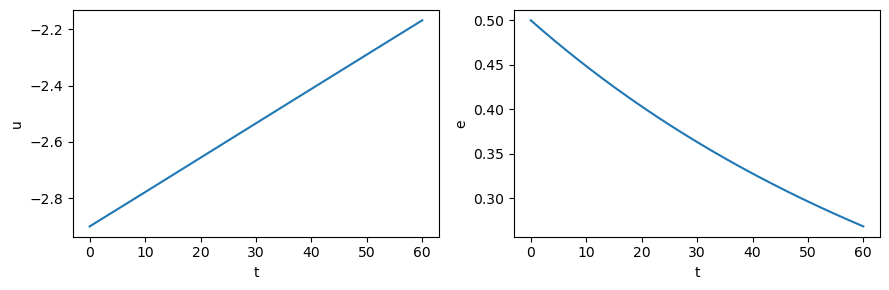

In [11]:
table_arrays = table.precontract({"nu": 0.2, "chi": 0.5}).raw()
ws = table_arrays.workspace()
out = np.empty(table_arrays.n_outputs)


@njit
def averaged_rhs(t, y, coeffs, shape, bounds, tol, scratch, work, out):
    status = eval_into(coeffs, shape, bounds, tol, y, scratch, work, out)
    if status:
        raise ValueError("the solution left the table")
    return out.copy()


y0 = [-2.9, 0.5]
sol = solve_ivp(lambda t, y: averaged_rhs(t, y, *table_arrays, *ws, out), (0, 60), y0,
                method="DOP853", rtol=1e-10, atol=1e-12, dense_output=True)
ref = solve_ivp(lambda t, y: np.array(rates(0.2, *y, 0.5)), (0, 60), y0,
                method="DOP853", rtol=1e-10, atol=1e-12, dense_output=True)
t = np.linspace(0, 60, 200)
print(f"{sol.nfev} right-hand side calls; max difference from the exact rates: "
      f"{np.abs(sol.sol(t) - ref.sol(t)).max():.1e}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(t, sol.sol(t)[0]); ax[0].set_xlabel("t"); ax[0].set_ylabel("u")
ax[1].plot(t, sol.sol(t)[1]); ax[1].set_xlabel("t"); ax[1].set_ylabel("e")
fig.tight_layout()

## 5. Gradients through domain maps: a Hamiltonian

The equations of motion of a Hamiltonian are its gradient. Here
`H(r, p_r, p_phi)` is the Newtonian two-body Hamiltonian, tabulated on a grid
placed with two maps:

- `r` is stored as `u = 1/r`, in which H is much closer to a polynomial;
- `p_phi` is stored relative to its circular-orbit value `sqrt(r)`, a
  *boundary function* given by its own small table, so the table covers a
  band around the circular orbits rather than a box.

A `ChebyshevGrid` gives the physical points to sample at, and `fit` returns a
`MappedInterpolant` that is evaluated, and differentiated, in the physical
variables.

In [12]:
r_range = (6.0, 16.0)
rn = chebyshev_nodes(20, *r_range)
boundary = ChebyshevInterpolantND(np.sqrt(rn)[:, None], [r_range], axis_names=["r"],
                                  output_names=["pphi_circ"])
inv_r = AxisMap("power", power=-1)

grid = ChebyshevGrid([
    Axis("r", 30, inv_r.table_domain(*r_range), inv_r),
    Axis("pr", 4, (-0.15, 0.15)),
    Axis("pphi", 5, (-0.8, 0.6), AxisMap(lower="pphi_circ")),
], boundary=boundary)


def hamiltonian(r, pr, pphi):
    return 0.5 * pr**2 + 0.5 * pphi**2 / r**2 - 1 / r


H = grid.fit(hamiltonian(*grid.physical_points().T))
print(H)
value, grad = H.value_and_grad(10.0, 0.05, 3.1)
print("dH/dr, dH/dp_r, dH/dp_phi:", grad)

MappedInterpolant(axes=('r', 'pr', 'pphi'), maps={'r': AxisMap('power', power=-1.0), 'pphi': AxisMap('identity', lower='pphi_circ')}, boundary=('pphi_circ',), table=ChebyshevInterpolantND(axes=('r', 'pr', 'pphi'), grid_shape=(30, 4, 5), kmax=(30, 4, 5), outputs=1, nodes='Chebyshev', dtype=float64))
dH/dr, dH/dp_r, dH/dp_phi: [0.00039 0.05    0.031  ]


`eval_grad_physical_into` evaluates the boundary table, the maps, the table
and the chain rule in one compiled call, so Hamilton's equations can be
written directly:

deviation from the Kepler ellipse r = p / (1 + e cos phi): 5.5e-12


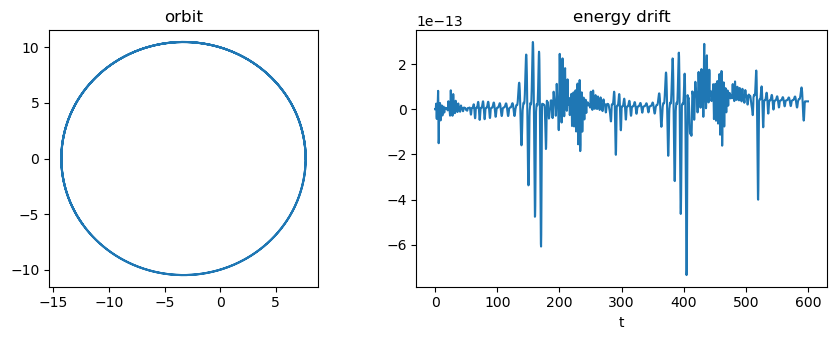

In [13]:
H_arrays = H.raw()
H_ws = H_arrays.workspace()
H_out = np.empty((4, 1))


@njit
def hamilton(t, y, coeffs, shape, bounds, tol, codes, params, bcoeffs, bshape, bbounds, baxes,
             scratch, work, out):
    r, phi, pr, pphi = y
    status = eval_grad_physical_into(coeffs, shape, bounds, tol, codes, params, bcoeffs, bshape,
                                     bbounds, baxes, np.array([r, pr, pphi]), scratch, work, out)
    if status:
        raise ValueError("the orbit left the table")
    dH_dr, dH_dpr, dH_dpphi = out[1, 0], out[2, 0], out[3, 0]
    return np.array([dH_dpr, dH_dpphi, -dH_dr, 0.0])


p, e = 10.0, 0.3                                      # semi-latus rectum, eccentricity
y0 = [p / (1 + e), 0.0, 0.0, np.sqrt(p)]
orbit = solve_ivp(lambda t, y: hamilton(t, y, *H_arrays, *H_ws, H_out), (0, 600), y0,
                  method="DOP853", rtol=1e-12, atol=1e-12, dense_output=True)
r, phi, pr, pphi = orbit.sol(np.linspace(0, 600, 2000))
energy = H.evaluate_batch(np.stack([r, pr, pphi], axis=1))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].plot(r * np.cos(phi), r * np.sin(phi)); ax[0].set_aspect("equal"); ax[0].set_title("orbit")
ax[1].plot(np.linspace(0, 600, 2000), energy - energy[0]); ax[1].set_xlabel("t")
ax[1].set_title("energy drift")
fig.tight_layout()
print("deviation from the Kepler ellipse r = p / (1 + e cos phi):",
      f"{np.abs(r / (p / (1 + e * np.cos(phi))) - 1).max():.1e}")

## 6. Sampling in chunks, and saving tables

Real tables can take hours or days to sample, so the grid's nodes are
numbered and split into chunks that separate jobs can compute. Each job saves
its chunk; `load_chunks` checks that the chunks belong to this grid and cover
every node exactly once, and `fit` builds the table.

In [14]:
workdir = Path(tempfile.mkdtemp())
paths = []
for start, stop in grid.chunks(200):                  # in practice: one job per chunk
    x = grid.physical_points(start, stop)
    path = workdir / f"chunk_{start}.npz"
    grid.save_chunk(path, start, stop, {"H": hamiltonian(*x.T)})
    paths.append(path)

H_chunked = grid.fit(grid.load_chunks(paths))
print(len(paths), "chunks; same coefficients as the direct fit:",
      np.array_equal(H_chunked.table.get_coefficients()[..., 0], H.table.get_coefficients()))

3 chunks; same coefficients as the direct fit: True


`save` writes tables (and grids) to HDF5 with any metadata, and `load` reads
them back bit for bit, optionally straight onto the GPU with
`load(path, device="cuda")`. The file layout is documented, so other code can
read the tables too.

In [15]:
save(workdir / "hamiltonian.h5", H_chunked,
     metadata={"model": "Newtonian two-body (toy)", "grid_hash": grid.grid_hash()})
H_loaded = load(workdir / "hamiltonian.h5")
print(read_metadata(workdir / "hamiltonian.h5")["model"])
print("identical:", np.array_equal(H_loaded.evaluate(10.0, 0.05, 3.1), H_chunked.evaluate(10.0, 0.05, 3.1)))

Newtonian two-body (toy)
identical: True


## On the GPU

Everything batched also runs on CUDA through CuPy (`pip install
chebyshevnd[gpu]`): pass CuPy arrays to `evaluate_batch`,
`value_and_grad_batch` or `precontract_batch`, and the tables are copied to
the GPU once and kept there. For example:

```python
import cupy as cp

batch = table.precontract_batch({"nu": cp.asarray(nu_values)})   # tables on the GPU
values, grads = batch.value_and_grad(cp.asarray(states))          # one call per RHS step
```